# RoboDojo with a RoboJEPA baseline

[RoboDojo](https://github.com/RoboDojo-Benchmark/RoboDojo) is a dual-arm manipulation benchmark simulated in Isaac Sim. Its evaluation client drives a policy server from [XPolicyLab](https://github.com/XPolicyLab/XPolicyLab) over WebSocket, so a torch-world policy runs in its own environment as that server's model, `RoboDojoPolicy`, and is scored on RoboDojo's own layouts.

This notebook trains [RoboJEPA](../../docs/models/jepa/robojepa.md) on RoboDojo's 100 demonstrations of `stack_bowls`, "Stack the three bowls together", by two ARX X5 arms seen by the head camera. It measures prediction and planning on held-out demonstrations, then serves the planner through XPolicyLab's real server and client, exactly as RoboDojo calls it. Closed-loop scoring runs in RoboDojo's Isaac Sim client and is not part of this notebook.

XPolicyLab is needed on the Python path to decode RoboDojo's JPEG frames and to run the server; set `XPOLICYLAB` to its checkout.

In [1]:
import asyncio
import os
import sys
import threading
import time

import numpy as np
import torch
import torch.nn.functional as F
from huggingface_hub import HfFileSystem
from torch import nn
from torch.utils.data import ConcatDataset, DataLoader

from torch_world import plots
from torch_world.datasets import TrajectoryDataset, load_robodojo
from torch_world.datasets.robodojo import robot_layout
from torch_world.evaluation import RoboDojoPolicy
from torch_world.models import RoboJEPA
from torch_world.planning import CEM

sys.path.insert(0, os.environ.get("XPOLICYLAB", "../../third_party/XPolicyLab"))  # an XPolicyLab checkout
torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
amp = torch.autocast(device, dtype=torch.bfloat16)  # matmuls in bf16; losses and planner statistics stay float32
FRAMESKIP, WINDOW, GRID, SIZE = 5, 4, (8, 8), 64

/clusterhome/kleyton/pytorch-world-benchmarks-20261018/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Data

Each demonstration is an HDF5 file of 640 × 480 JPEG frames from three cameras, joint states and joint targets at 25 Hz, 46 GB for the task. `load_robodojo` reads an open file, so through `HfFileSystem` only the head camera and the robot arrays are fetched. It decodes the frames with XPolicyLab, resizes them to 64 × 64 and packs both arms' joints and grippers into 14 values. The resized episodes are cached.

'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/RoboDojo-Benchmark/RoboDojo/resolve/main/data/RoboDojo/stack_bowls/arx_x5/data/episode_0000072.hdf5


Retrying in 1s [Retry 1/5].


'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/RoboDojo-Benchmark/RoboDojo/resolve/main/data/RoboDojo/stack_bowls/arx_x5/data/episode_0000072.hdf5


Retrying in 2s [Retry 2/5].


'The read operation timed out' thrown while requesting GET https://huggingface.co/datasets/RoboDojo-Benchmark/RoboDojo/resolve/main/data/RoboDojo/stack_bowls/arx_x5/data/episode_0000072.hdf5


Retrying in 4s [Retry 3/5].


100 demonstrations, 44774 steps, 203 to 779 each


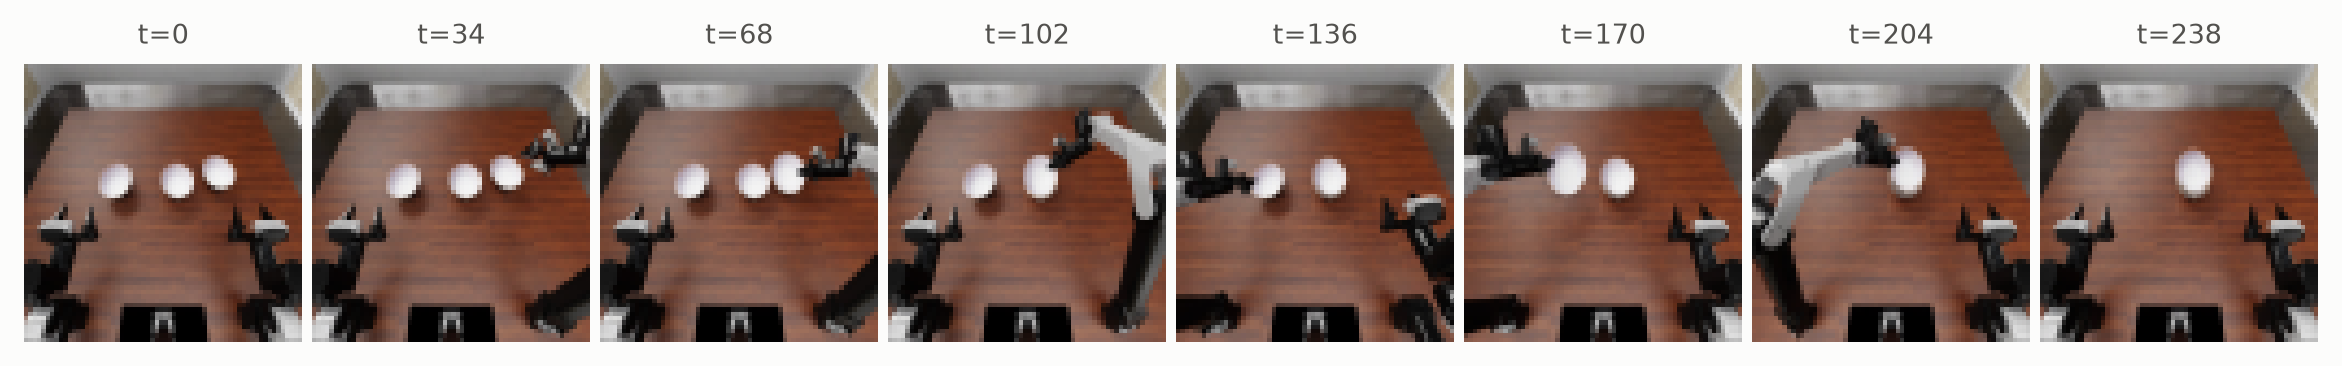

In [2]:
CACHE = "data/robodojo/stack_bowls_64.pt"
if not os.path.exists(CACHE):
    fs = HfFileSystem()
    files = sorted(fs.glob("datasets/RoboDojo-Benchmark/RoboDojo/data/RoboDojo/stack_bowls/arx_x5/data/*.hdf5"))
    episodes = []
    for path in files:
        with fs.open(path, "rb", block_size=8 * 2**20) as file:
            episodes.append(load_robodojo(file, size=SIZE))
    os.makedirs(os.path.dirname(CACHE), exist_ok=True)
    torch.save(episodes, CACHE)
episodes = torch.load(CACHE)
lengths = [e["actions"].shape[1] for e in episodes]
print(f"{len(episodes)} demonstrations, {sum(lengths)} steps, {min(lengths)} to {max(lengths)} each")
plots.images(episodes[0]["observations"][0, :: lengths[0] // 7][:8], [f"t={t}" for t in range(0, lengths[0], lengths[0] // 7)][:8], ncols=8)

Ten demonstrations are held out. At 25 Hz a joint target is nearly the current joint state, so the model reads and the planner chooses **offsets** from the current state; they are scaled to [-1, 1] by the 99th percentile of each joint's offsets in the training demonstrations.

In [3]:
train, test = episodes[:90], episodes[90:]
offsets = torch.cat([(e["actions"] - e["states"])[0] for e in train])
scale = offsets.abs().quantile(0.99, dim=0).clamp(min=1e-3)


def windows(episode):
    offset = ((episode["actions"] - episode["states"]) / scale).clamp(-1, 1)
    return TrajectoryDataset({"observations": episode["observations"], "actions": offset}, window=WINDOW, frameskip=FRAMESKIP)


loader = DataLoader(ConcatDataset([windows(e) for e in train]), batch_size=64, shuffle=True, drop_last=True, num_workers=4)
print(f"{len(loader.dataset)} training windows")

39840 training windows


## Model

The same simple RoboJEPA as the OGBench notebook: raw 8 × 8 pixel patches of one camera, and one token per chunk of five 14-value offsets.

In [4]:
class Patchify(nn.Module):
    def forward(self, x):
        return F.pixel_unshuffle(x, 8).flatten(2).transpose(1, 2)


def frames(observations):
    x = observations.float() / 255 if observations.dtype == torch.uint8 else observations
    return x.unsqueeze(2)


model = RoboJEPA(
    embed_dim=192, action_dim=14 * FRAMESKIP, num_views=1, predictor_dim=256, depth=6, num_heads=4,
    window=WINDOW, rollout_steps=2, encoder=Patchify(),
).to(device)
print(f"{sum(p.numel() for p in model.parameters()) / 1e6:.2f}M parameters")

4.86M parameters


## Train

10000 updates in 35.0 min


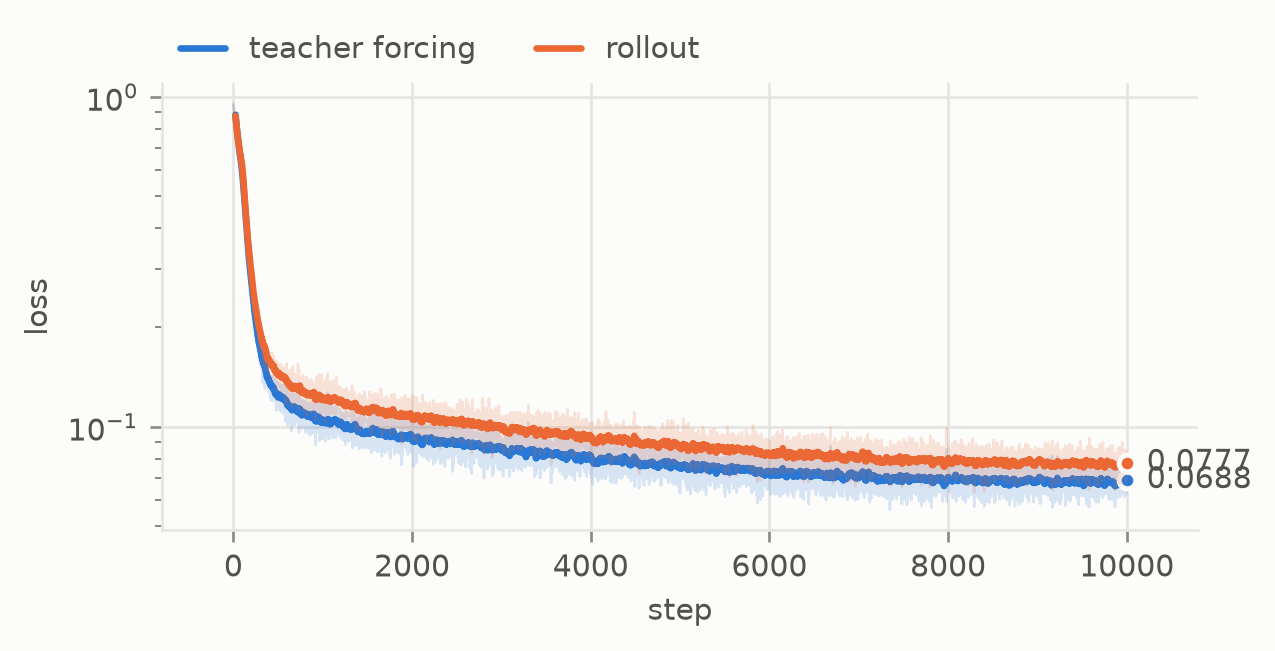

In [5]:
STEPS = 10000
opt = torch.optim.AdamW(model.parameters(), lr=3e-4, weight_decay=0.04)
sched = torch.optim.lr_scheduler.OneCycleLR(opt, max_lr=3e-4, total_steps=STEPS, pct_start=0.05)
log, step, tic = {"teacher forcing": [], "rollout": []}, 0, time.perf_counter()
model.train()
while step < STEPS:
    for batch in loader:
        z = model.encode(frames(batch["observations"].to(device)), GRID)
        with amp:
            out = model(z, batch["actions"].to(device))
        opt.zero_grad(set_to_none=True)
        out["loss"].backward()
        opt.step()
        sched.step()
        log["teacher forcing"].append(out["tf_loss"].item())
        log["rollout"].append(out["rollout_loss"].item())
        step += 1
        if step == STEPS:
            break
model.eval()
print(f"{STEPS} updates in {(time.perf_counter() - tic) / 60:.1f} min")
plots.curves(log)

## Held-out demonstrations

Next-latent error on every window of the held-out demonstrations, against copying the last latent forward. With the true offsets the model should beat persistence; with the offsets of another moment of the demonstration it should lose that advantage, which shows it reads the actions.

In [6]:
errors = {"RoboJEPA": [], "RoboJEPA, shuffled actions": [], "persistence": []}
with torch.no_grad():
    for episode in test:
        data = windows(episode)
        batch = [data[i] for i in range(len(data))]
        z = model.encode(frames(torch.stack([b["observations"] for b in batch]).to(device)), GRID)
        actions = torch.stack([b["actions"] for b in batch]).to(device)
        shuffled = actions[torch.randperm(len(actions), generator=torch.Generator().manual_seed(0))]
        with amp:
            pred = model.predict(z[:, :-1], actions[:, :-1]).float()
            wrong = model.predict(z[:, :-1], shuffled[:, :-1]).float()
        errors["RoboJEPA"].append((pred[:, -1] - z[:, -1]).abs().mean().item())
        errors["RoboJEPA, shuffled actions"].append((wrong[:, -1] - z[:, -1]).abs().mean().item())
        errors["persistence"].append((z[:, -2] - z[:, -1]).abs().mean().item())
for name, e in errors.items():
    print(f"{name:28s} next-latent L1 {np.mean(e):.4f}")

RoboJEPA                     next-latent L1 0.1171
RoboJEPA, shuffled actions   next-latent L1 0.1601
persistence                  next-latent L1 0.1327


## Planning on held-out demonstrations

Given a frame of a held-out demonstration and the frame 25 steps (one second) later as the goal, CEM plans five chunks of offsets. Its first chunk is compared with the demonstrator's offsets, in normalized units, alongside holding still (zero offsets) and random offsets. Matching the demonstrator is a proxy: other motions may reach the goal too.

In [7]:
planner = CEM(horizon=5, action_dim=14 * FRAMESKIP, num_samples=128, num_elites=16, iterations=5, bounds=(-1, 1))
AHEAD = 5 * FRAMESKIP
gaps = {"RoboJEPA + CEM": [], "hold still": [], "random": []}
for episode in test:
    obs = episode["observations"][0]
    expert_offsets = ((episode["actions"] - episode["states"])[0] / scale).clamp(-1, 1)
    starts = torch.arange(0, len(obs) - AHEAD, 10)
    with torch.no_grad(), amp:
        z = model.encode(frames(obs[starts, None].to(device)), GRID)
        goal = model.encode(frames(obs[starts + AHEAD, None].to(device)), GRID)[:, 0]
        plan = planner(model, z, goal).float().cpu()[:, 0].view(len(starts), FRAMESKIP, 14)
    expert = torch.stack([expert_offsets[s : s + FRAMESKIP] for s in starts])
    gaps["RoboJEPA + CEM"].append((plan - expert).abs().mean(-1).flatten())
    gaps["hold still"].append(expert.abs().mean(-1).flatten())
    gaps["random"].append((torch.rand_like(expert) * 2 - 1 - expert).abs().mean(-1).flatten())
for name, g in gaps.items():
    print(f"{name:16s} mean |offset - demonstration| {torch.cat(g).mean():.3f}")

RoboJEPA + CEM   mean |offset - demonstration| 0.272
hold still       mean |offset - demonstration| 0.097
random           mean |offset - demonstration| 0.523


## Serve to RoboDojo

The XPolicyLab policy folder's `model.py` subclasses `RoboDojoPolicy` with a policy from observations to action chunks. Here the policy plans toward the last frame of a held-out demonstration and returns its first chunk: five offsets, which `relative=True` adds to the current joint state and `action_bounds` scales to radians.

In [8]:
goal_frame = test[0]["observations"][0, -1]


def plan_chunk(observations):
    z = model.encode(frames(observations[:, None].to(device)), GRID)
    goal = model.encode(frames(goal_frame.expand(len(observations), -1, -1, -1)[:, None].to(device)), GRID)[:, 0]
    with amp:
        return planner(model, z, goal)[:, 0].float().view(-1, FRAMESKIP, 14)


class Model(RoboDojoPolicy):  # XPolicyLab/policy/TorchWorld/model.py
    def __init__(self, deploy_cfg):
        super().__init__(
            plan_chunk, camera="cam_head", size=SIZE, action_bounds=(-scale, scale), relative=True, device=device
        )

XPolicyLab's own server hosts the model, and its own client sends held-out observations the way RoboDojo's evaluation client does: JPEG-encoded frames from all three cameras plus the robot state, for two environments at once.

In [9]:
from XPolicyLab.client_server.ws.model_client import WsModelClient
from XPolicyLab.client_server.ws.model_server import PolicyServer, PolicyServerConfig
from XPolicyLab.utils.process_data import encode_image_bit

server = PolicyServer(Model({}), PolicyServerConfig(host="127.0.0.1", port=8765))
threading.Thread(target=lambda: asyncio.run(server.serve_forever()), daemon=True).start()
time.sleep(2)
client = WsModelClient(url="ws://127.0.0.1:8765", evaluation_id="notebook", trial_id="demo", action_case_id="demo")


def observation(env_idx, t):
    image = test[0]["observations"][0, t].permute(1, 2, 0).numpy()
    image = np.ascontiguousarray(np.kron(image, np.ones((8, 10, 1), np.uint8)))  # back to a 640 x 512 camera frame
    state = test[0]["states"][0, t].numpy()
    fields, offset = {}, 0
    for key, width in robot_layout():
        fields[key], offset = state[offset : offset + width], offset + width
    vision = {cam: {"color": encode_image_bit(image)} for cam in ("cam_head", "cam_left_wrist", "cam_right_wrist")}
    return {"env_idx": env_idx, "vision": vision, "state": fields, "instruction": "Stack the three bowls together."}


client.call(func_name="reset")
client.call(func_name="update_obs_batch", obs=[observation(0, 0), observation(1, 40)])
chunks = client.call(func_name="get_action_batch", obs=[0, 1])
for env_idx, chunk in enumerate(chunks):
    print(f"env {env_idx}: {len(chunk)} actions; first:")
    print("   ", {k: np.round(np.asarray(v), 3).tolist() for k, v in chunk[0].items()})
client.close()

[CONNECTING] websocket policy server ws://127.0.0.1:8765 (attempt 1/180, timeout=30s)


[CONNECTED] websocket policy server connected: ws://127.0.0.1:8765


env 0: 5 actions; first:
    {'left_arm_joint_state': [0.004999999888241291, -0.0, -0.007000000216066837, -0.008999999612569809, 0.013000000268220901, -0.0], 'left_ee_joint_state': [1.0219999551773071], 'right_arm_joint_state': [-0.0010000000474974513, 0.0010000000474974513, -0.04899999871850014, 0.01899999938905239, 0.0010000000474974513, -0.004999999888241291], 'right_ee_joint_state': [0.9959999918937683]}
env 1: 5 actions; first:
    {'left_arm_joint_state': [-0.008999999612569809, 0.05000000074505806, -0.004000000189989805, 0.006000000052154064, -0.0020000000949949026, -0.014000000432133675], 'left_ee_joint_state': [0.9660000205039978], 'right_arm_joint_state': [-0.10499999672174454, 1.059999942779541, 0.7630000114440918, -0.8700000047683716, -0.414000004529953, -0.061000000685453415], 'right_ee_joint_state': [0.0560000017285347]}


These are the action dicts RoboDojo's `take_action_batch` validates and executes. To score the policy, put this `Model` in `XPolicyLab/policy/TorchWorld/model.py`, copy `deploy.py` and `deploy.yml` from `policy/DP/`, and start the server and RoboDojo's evaluation client as its README describes.